# Fase 2: Penyusutan Dimensi Data (204 → 203 → 74 → 37)

Pada fase ini, data mentah berdimensi tinggi yang diperoleh dari Fase 1 (**37 observasi × 204 fitur**) akan melalui proses reduksi bertingkat. Alurnya adalah sebagai berikut:

$$204 \xrightarrow{\text{Seleksi Tahap I}} 203 \xrightarrow{\text{Seleksi Tahap II}} 74 \xrightarrow{\text{Transformasi PCA}} 37$$

---

## Alasan Utama Tidak Menggunakan PCA Secara Penuh

Mengapa tidak langsung melakukan PCA dari 204 ke 74 komponen? Algoritma PCA memiliki batasan matematis: jumlah komponen maksimum yang dapat dibentuk adalah **min(jumlah observasi, jumlah atribut)**. Karena dataset kita hanya memiliki 37 observasi (wilayah), PCA maksimal hanya bisa memproduksi 37 komponen.

Mencoba memaksakan `PCA(n_components=203)` atau `PCA(n_components=74)` akan memicu galat (error) dimensi.

Oleh karena itu, strategi yang digunakan adalah:
1. **Penyusutan 1 & 2 (204 → 203 → 74):** Menggunakan teknik **Feature Selection** berbasis korelasi. Atribut yang memiliki informasi redundan (sangat berkorelasi dengan atribut lain) akan dieliminasi.
2. **Penyusutan 3 (74 → 37):** Menggunakan **Principal Component Analysis (PCA)** untuk mengekstrak 37 dimensi orthogonal dari 74 fitur tersisa.

| Fase | Perubahan Dimensi | Pendekatan | Penjelasan |
| :--- | :---: | :--- | :--- |
| **Tahap I** | 204 → 203 | Seleksi Fitur Korelasi | Menggugurkan 1 fitur dengan redundansi tertinggi |
| **Tahap II** | 203 → 74 | Seleksi Fitur Korelasi | Menggugurkan 129 fitur yang memuat informasi berulang |
| **Tahap III** | 74 → 37 | Dekomposisi PCA | Memproyeksikan sisa fitur ke dalam 37 Komponen Utama |

## 2.1 Persiapan Pustaka dan Impor Data Sebelumnya

Kita muat data *Pickle* yang sebelumnya disimpan pada Tahap 1.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Konfigurasi visualisasi
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style='darkgrid', palette='muted', font_scale=1.0)

# Penentuan direktori input dan output
DIR_INPUT = '../data/hasil_tahap1'
DIR_OUTPUT = '../data/hasil_tahap2'
os.makedirs(DIR_OUTPUT, exist_ok=True)

path_data_awal = os.path.join(DIR_INPUT, 'koleksi_data_tahap1.pkl')

if not os.path.exists(path_data_awal):
    raise FileNotFoundError(f"File data tahap 1 tidak ditemukan di {path_data_awal}. Pastikan notebook Tahap 1 sudah dijalankan.")

with open(path_data_awal, 'rb') as file_obj:
    data_tahap1 = pickle.load(file_obj)

# Ekstraksi komponen data
fitur_linier = data_tahap1['fitur_lin']
fitur_polinomial = data_tahap1['fitur_pol']
meta_linier = data_tahap1['meta_lin']
meta_polinomial = data_tahap1['meta_pol']

JUMLAH_OBSERVASI = fitur_polinomial.shape[0]

print(f"Data Tahap 1 berhasil dimuat dari: {os.path.abspath(DIR_INPUT)}")
print(f" Dimensi Data Linier     : {fitur_linier.shape}")
print(f" Dimensi Data Polinomial : {fitur_polinomial.shape}")

Data Tahap 1 berhasil dimuat dari: c:\Users\HYPE AMD\Documents\kuliah\psd\data\hasil_tahap1
 Dimensi Data Linier     : (37, 204)
 Dimensi Data Polinomial : (37, 204)


## 2.2 Penyetaraan Skala (Standardization)

Sebelum PCA dilakukan di akhir, setiap fitur wajib dinormalisasi agar memiliki rata-rata ($\mu$) = 0 dan standar deviasi ($\sigma$) = 1 menggunakan algoritma `StandardScaler`. Ini krusial agar fitur dengan rentang nilai besar tidak mendominasi pembentukan komponen.

Statistik Pasca-Standardisasi:
 Data Linier     -> Mean: 0.0000, Std Dev: 0.9852
 Data Polinomial -> Mean: 0.0000, Std Dev: 0.9877


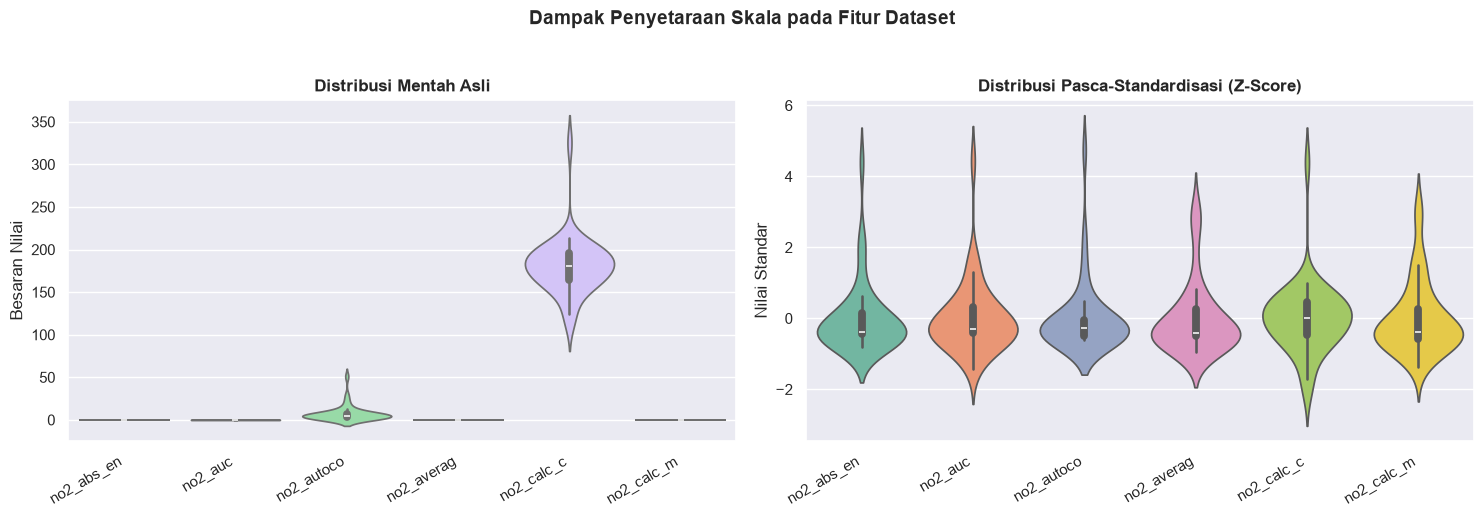

In [2]:
# Proses standardisasi (Z-score normalization)
penyetara_lin = StandardScaler()
penyetara_pol = StandardScaler()

X_skala_lin = penyetara_lin.fit_transform(fitur_linier)
X_skala_pol = penyetara_pol.fit_transform(fitur_polinomial)

print('Statistik Pasca-Standardisasi:')
print(f" Data Linier     -> Mean: {X_skala_lin.mean():.4f}, Std Dev: {X_skala_lin.std():.4f}")
print(f" Data Polinomial -> Mean: {X_skala_pol.mean():.4f}, Std Dev: {X_skala_pol.std():.4f}")

# Visualisasi perbandingan distribusi pada 6 atribut perdana (Polinomial)
batas_vis = min(6, fitur_polinomial.shape[1])
kolom_sampel = list(fitur_polinomial.columns[:batas_vis])
label_sumbu = [teks[:10] for teks in kolom_sampel]

fig, (ax_kiri, ax_kanan) = plt.subplots(1, 2, figsize=(15, 5))

# Plot sebelum standardisasi
sns.violinplot(data=fitur_polinomial[kolom_sampel], ax=ax_kiri, palette="pastel")
ax_kiri.set_xticklabels(label_sumbu, rotation=30, ha='right')
ax_kiri.set_title('Distribusi Mentah Asli', fontweight='bold')
ax_kiri.set_ylabel('Besaran Nilai')

# Plot sesudah standardisasi
sns.violinplot(data=pd.DataFrame(X_skala_pol[:, :batas_vis], columns=kolom_sampel), ax=ax_kanan, palette="Set2")
ax_kanan.set_xticklabels(label_sumbu, rotation=30, ha='right')
ax_kanan.set_title('Distribusi Pasca-Standardisasi (Z-Score)', fontweight='bold')
ax_kanan.set_ylabel('Nilai Standar')

plt.suptitle('Dampak Penyetaraan Skala pada Fitur Dataset', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '01_visualisasi_standardisasi.png'), dpi=120)
plt.show()

## 2.3 Evaluasi Batas Maksimal Komponen PCA

Membuktikan secara empiris bahwa data berdimensi $37 \times 204$ hanya mampu mengekstrak maksimal 37 komponen PCA, dan kita akan melihat seberapa cepat variansi kumulatif mencapai angka ideal (misal 99%).

[  Interpolasi Linier  ] Dimensi Asli: 204 -> Batas PCA: 37 | Target 99% tercapai pada komponen ke-26
[Interpolasi Polinomial] Dimensi Asli: 204 -> Batas PCA: 37 | Target 99% tercapai pada komponen ke-27


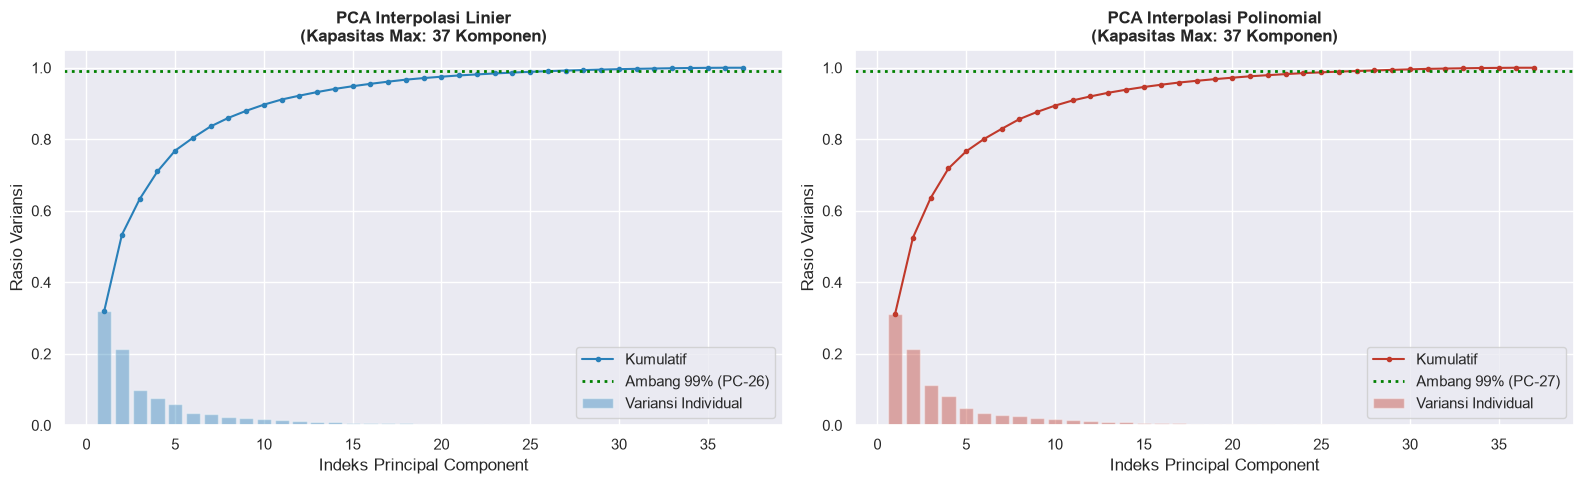


# Uji Coba Pelanggaran Dimensi PCA (Mensimulasikan Error)
 X_Gagal menjalankan PCA(n_components=203) -> Pesan Sistem: n_components=203 must be between 0 and min(n_samples, n_features)=37 with svd_solver='full'
 X_Gagal menjalankan PCA(n_components=74) -> Pesan Sistem: n_components=74 must be between 0 and min(n_samples, n_features)=37 with svd_solver='full'


In [3]:
fig, diagram = plt.subplots(1, 2, figsize=(16, 5))
konfig_uji = [
    (diagram[0], X_skala_lin, 'Interpolasi Linier', '#2980b9'),
    (diagram[1], X_skala_pol, 'Interpolasi Polinomial', '#c0392b')
]

for ax, data_uji, judul, warna in konfig_uji:
    # Memaksa PCA mengekstrak komponen sebanyak mungkin
    model_pca_uji = PCA(random_state=101).fit(data_uji)
    
    variansi_kolektif = np.cumsum(model_pca_uji.explained_variance_ratio_)
    sumbu_x = np.arange(1, len(variansi_kolektif) + 1)
    
    # Mencari titik di mana variansi 99% tercapai
    titik_99 = int(np.argmax(variansi_kolektif >= 0.99) + 1)
    
    ax.bar(sumbu_x, model_pca_uji.explained_variance_ratio_, color=warna, alpha=0.4, label='Variansi Individual')
    ax.plot(sumbu_x, variansi_kolektif, marker='.', color=warna, linewidth=1.5, label='Kumulatif')
    
    ax.axhline(0.99, color='green', linestyle=':', linewidth=2, label=f'Ambang 99% (PC-{titik_99})')
    
    ax.set_title(f"PCA {judul}\n(Kapasitas Max: {model_pca_uji.n_components_} Komponen)", fontweight='bold')
    ax.set_xlabel('Indeks Principal Component')
    ax.set_ylabel('Rasio Variansi')
    ax.legend(loc='lower right')
    
    print(f"[{judul:^22}] Dimensi Asli: {data_uji.shape[1]} -> Batas PCA: {model_pca_uji.n_components_} | Target 99% tercapai pada komponen ke-{titik_99}")

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '02_evaluasi_batas_pca.png'), dpi=120)
plt.show()

print("\n# Uji Coba Pelanggaran Dimensi PCA (Mensimulasikan Error)")
for target_k in [203, 74]:
    try:
        PCA(n_components=target_k).fit(X_skala_pol)
    except Exception as error_msg:
        print(f" X_Gagal menjalankan PCA(n_components={target_k}) -> Pesan Sistem: {str(error_msg)}")

## 2.4 Pembuatan Fungsi Pendukung Utama

Kita merancang beberapa fungsionalitas untuk mempermudah proses pemangkasan (seleksi fitur) dan ekstraksi PCA secara berulang.

In [4]:
def pangkas_fitur_berkorelasi(dataframe_fitur, limit_target, label_log="Dataset"):
    """
    Menyusutkan dimensi dengan mengeliminasi atribut yang identik/redundan.
    Algoritma:
    1. Buang atribut tak bervariasi (standar deviasi = 0).
    2. Identifikasi pasangan atribut dengan korelasi Pearson tertinggi.
    3. Dari pasangan tersebut, buang atribut yang rata-rata korelasinya terhadap sisa atribut lain lebih tinggi.
    """
    kumpulan_kolom = list(dataframe_fitur.columns)
    daftar_buang = []
    
    # 1. Bersihkan fitur konstan
    fitur_statis = [k for k in kumpulan_kolom if dataframe_fitur[k].std() == 0 or np.isnan(dataframe_fitur[k].std())]
    for ft in fitur_statis[: max(0, len(kumpulan_kolom) - limit_target)]:
        daftar_buang.append(ft)
        
    sisa_kolom = [k for k in kumpulan_kolom if k not in daftar_buang]
    
    # 2. Eliminasi iteratif berbasis matriks korelasi
    matriks_korelasi = np.array(dataframe_fitur[sisa_kolom].corr().abs().fillna(0), dtype=float)
    np.fill_diagonal(matriks_korelasi, 0.0) # Abaikan korelasi diri sendiri
    
    status_aktif = np.ones(len(sisa_kolom), dtype=bool)
    
    while status_aktif.sum() > limit_target:
        indeks_aktif = np.where(status_aktif)[0]
        sub_matriks = matriks_korelasi[np.ix_(indeks_aktif, indeks_aktif)]
        
        # Cari titik korelasi maksimum
        baris, kolom = np.unravel_index(np.argmax(sub_matriks), sub_matriks.shape)
        idx_global_1, idx_global_2 = indeks_aktif[baris], indeks_aktif[kolom]
        
        # Bandingkan rata-rata korelasi untuk menentukan mana yang dibuang
        rata_korelasi_1 = matriks_korelasi[idx_global_1, indeks_aktif].mean()
        rata_korelasi_2 = matriks_korelasi[idx_global_2, indeks_aktif].mean()
        
        target_buang = idx_global_1 if rata_korelasi_1 >= rata_korelasi_2 else idx_global_2
        status_aktif[target_buang] = False
        daftar_buang.append(sisa_kolom[target_buang])
        
    kolom_final = [k for k, aktif in zip(sisa_kolom, status_aktif) if aktif]
    return kolom_final, daftar_buang


def skor_korelasi_rata_rata(dataframe_fitur):
    """Menghitung skor rata-rata korelasi absolut dari matriks. Semakin rendah, semakin baik (tidak redundan)."""
    matriks = np.array(dataframe_fitur.corr().abs().fillna(0), dtype=float)
    dim = matriks.shape[0]
    return (matriks.sum() - dim) / (dim * (dim - 1))


def eksekusi_pca(data_skala, jumlah_komponen, nama_dataset):
    model_pca = PCA(n_components=jumlah_komponen, random_state=42)
    hasil_transformasi = model_pca.fit_transform(data_skala)
    
    laju_variansi = np.cumsum(model_pca.explained_variance_ratio_)
    print(f" [PCA {nama_dataset}] Transformasi berhasil: {data_skala.shape[1]} -> {jumlah_komponen} Komponen Utama")
    print(f"  > Penguasaan Variansi PC-10 : {laju_variansi[min(9, jumlah_komponen-1)]:.2%}")
    print(f"  > Penguasaan Variansi Total : {laju_variansi[-1]:.2%}")
    
    return model_pca, hasil_transformasi, laju_variansi

print("Modul fungsional (pangkas_fitur_berkorelasi, skor_korelasi_rata_rata, eksekusi_pca) berhasil dikompilasi.")

Modul fungsional (pangkas_fitur_berkorelasi, skor_korelasi_rata_rata, eksekusi_pca) berhasil dikompilasi.


## 2.5 Penyusutan Tahap Pertama (204 → 203 Atribut)

Pembuangan 1 atribut yang memiliki indikasi duplikasi informasi paling tinggi atau bernilai konstan sepenuhnya.

In [5]:
print("--- FASE REDUKSI I (204 menuju 203) ---")
fitur203_lin, eliminasi1_lin = pangkas_fitur_berkorelasi(fitur_linier, 203, 'Set Linier')
fitur203_pol, eliminasi1_pol = pangkas_fitur_berkorelasi(fitur_polinomial, 203, 'Set Polinomial')

print(f" Dataset Linier     : Sisa {len(fitur203_lin)} atribut. Atribut tergusur: {eliminasi1_lin}")
print(f" Dataset Polinomial : Sisa {len(fitur203_pol)} atribut. Atribut tergusur: {eliminasi1_pol}")

# Buat salinan dataset dengan 203 fitur
df_linier_203 = fitur_linier[fitur203_lin]
df_polinomial_203 = fitur_polinomial[fitur203_pol]

--- FASE REDUKSI I (204 menuju 203) ---
 Dataset Linier     : Sisa 203 atribut. Atribut tergusur: ['no2_human_range_energy']
 Dataset Polinomial : Sisa 203 atribut. Atribut tergusur: ['no2_human_range_energy']


## 2.6 Penyusutan Tahap Kedua (203 → 74 Atribut)

Mengeliminasi 129 atribut lanjutan secara berulang. Fitur yang disisakan adalah sekumpulan 74 fitur yang memiliki variabilitas independen paling kuat.

--- FASE REDUKSI II (203 menuju 74) ---
 [Set Linier]      Pemangkasan 129 fitur sukses -> Dimensi baru: 37x74
 [Set Polinomial]  Pemangkasan 129 fitur sukses -> Dimensi baru: 37x74

Indeks Keterikatan (Rata-rata Nilai Korelasi Antar Fitur):
 ~ Basis Linier     : Menurun dari 0.3056 menjadi 0.2399 (Makin kecil makin independen)
 ~ Basis Polinomial : Menurun dari 0.3043 menjadi 0.2448


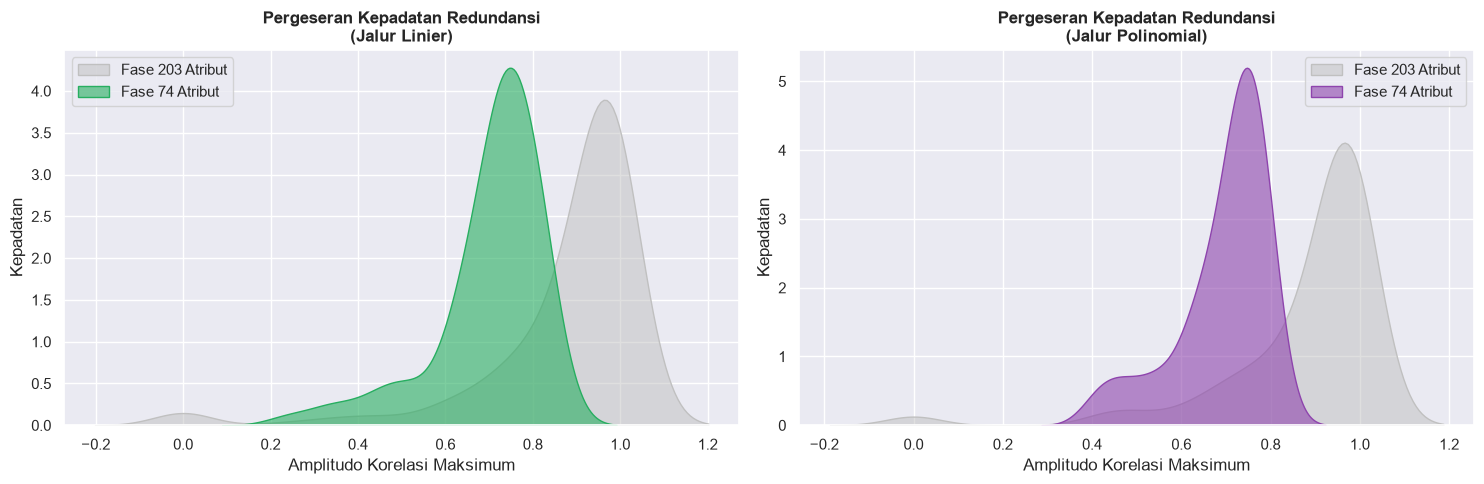

In [6]:
print("--- FASE REDUKSI II (203 menuju 74) ---")
fitur74_lin, eliminasi2_lin = pangkas_fitur_berkorelasi(df_linier_203, 74, 'Set Linier')
fitur74_pol, eliminasi2_pol = pangkas_fitur_berkorelasi(df_polinomial_203, 74, 'Set Polinomial')

df_linier_74 = fitur_linier[fitur74_lin]
df_polinomial_74 = fitur_polinomial[fitur74_pol]

print(f" [Set Linier]      Pemangkasan 129 fitur sukses -> Dimensi baru: 37x{len(fitur74_lin)}")
print(f" [Set Polinomial]  Pemangkasan 129 fitur sukses -> Dimensi baru: 37x{len(fitur74_pol)}")

# Evaluasi perbaikan redundansi data
skor_awal_lin = skor_korelasi_rata_rata(df_linier_203)
skor_akhir_lin = skor_korelasi_rata_rata(df_linier_74)
skor_awal_pol = skor_korelasi_rata_rata(df_polinomial_203)
skor_akhir_pol = skor_korelasi_rata_rata(df_polinomial_74)

print("\nIndeks Keterikatan (Rata-rata Nilai Korelasi Antar Fitur):")
print(f" ~ Basis Linier     : Menurun dari {skor_awal_lin:.4f} menjadi {skor_akhir_lin:.4f} (Makin kecil makin independen)")
print(f" ~ Basis Polinomial : Menurun dari {skor_awal_pol:.4f} menjadi {skor_akhir_pol:.4f}")

# Visualisasi pergeseran histogram korelasi maksimum
fig, pannel = plt.subplots(1, 2, figsize=(15, 5))

for ax, data_awal, data_akhir, nama_plot, kode_warna in [
    (pannel[0], df_linier_203, df_linier_74, 'Jalur Linier', '#27ae60'),
    (pannel[1], df_polinomial_203, df_polinomial_74, 'Jalur Polinomial', '#8e44ad')
]:
    def kalkulasi_korelasi_puncak(df):
        mat = np.array(df.corr().abs().fillna(0), dtype=float)
        np.fill_diagonal(mat, 0)
        return mat.max(axis=1)
    
    sns.kdeplot(kalkulasi_korelasi_puncak(data_awal), ax=ax, fill=True, color='silver', label='Fase 203 Atribut', alpha=0.5)
    sns.kdeplot(kalkulasi_korelasi_puncak(data_akhir), ax=ax, fill=True, color=kode_warna, label='Fase 74 Atribut', alpha=0.6)
    
    ax.set_title(f"Pergeseran Kepadatan Redundansi\n({nama_plot})", fontsize=12, fontweight='bold')
    ax.set_xlabel('Amplitudo Korelasi Maksimum')
    ax.set_ylabel('Kepadatan')
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '03_dampak_seleksi_korelasi.png'), dpi=120)
plt.show()

## 2.7 Transformasi Akhir dengan PCA (74 → 37 Komponen)

Langkah pemungkas: memampatkan 74 atribut hasil seleksi menjadi 37 komponen ruang orthogonal. Karena sampel = 37, rank matriks = 36 (setelah proses *centering*), komponen ke-37 mungkin mendekati 0, namun dibiarkan utuh demi keseragaman format dimensi.

--- FASE REDUKSI III (74 -> 37 dengan PCA) ---

 [PCA Jalur Linier] Transformasi berhasil: 74 -> 37 Komponen Utama
  > Penguasaan Variansi PC-10 : 81.15%
  > Penguasaan Variansi Total : 100.00%

 [PCA Jalur Polinomial] Transformasi berhasil: 74 -> 37 Komponen Utama
  > Penguasaan Variansi PC-10 : 81.81%
  > Penguasaan Variansi Total : 100.00%


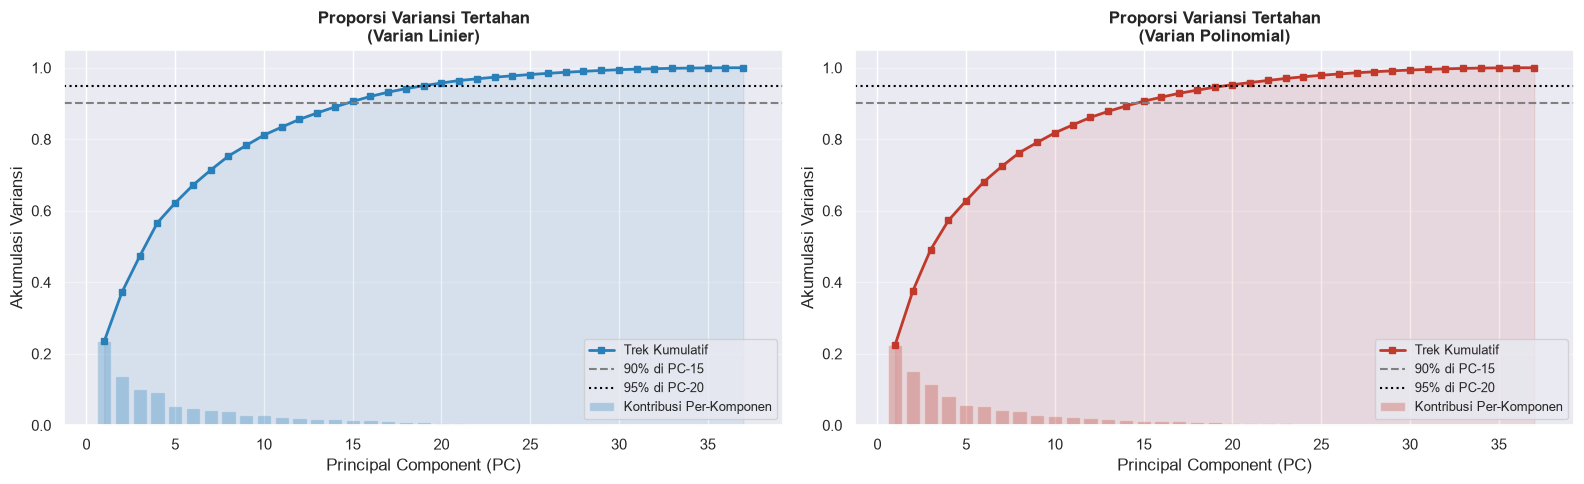

In [8]:
# Standarisasi data sisa 74 fitur terlebih dulu
std_lin_74 = StandardScaler().fit_transform(df_linier_74)
std_pol_74 = StandardScaler().fit_transform(df_polinomial_74)

print("--- FASE REDUKSI III (74 -> 37 dengan PCA) ---\n")
model_pca_lin, data_pca_lin, laju_var_lin = eksekusi_pca(std_lin_74, 37, 'Jalur Linier')
print("")
model_pca_pol, data_pca_pol, laju_var_pol = eksekusi_pca(std_pol_74, 37, 'Jalur Polinomial')

# Plot Scree & Cumulative Variance
fig, grafik = plt.subplots(1, 2, figsize=(16, 5))
sumbu_x = np.arange(1, 38)

for ax, laju_var, model_pca, label, warna in [
    (grafik[0], laju_var_lin, model_pca_lin, 'Varian Linier', '#2980b9'),
    (grafik[1], laju_var_pol, model_pca_pol, 'Varian Polinomial', '#c0392b')
]:
    ax.fill_between(sumbu_x, laju_var, color=warna, alpha=0.1)
    ax.plot(sumbu_x, laju_var, marker='s', color=warna, linewidth=2, markersize=4, label='Trek Kumulatif')
    ax.bar(sumbu_x, model_pca.explained_variance_ratio_, color=warna, alpha=0.3, label='Kontribusi Per-Komponen')
    
    # Penanda pencapaian variansi spesifik
    idx_90 = np.argmax(laju_var >= 0.90) + 1
    idx_95 = np.argmax(laju_var >= 0.95) + 1
    ax.axhline(0.90, color='grey', linestyle='dashed', label=f'90% di PC-{idx_90}')
    ax.axhline(0.95, color='black', linestyle='dotted', label=f'95% di PC-{idx_95}')
    
    ax.set_title(f"Proporsi Variansi Tertahan\n({label})", fontweight='bold')
    ax.set_xlabel('Principal Component (PC)')
    ax.set_ylabel('Akumulasi Variansi')
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(DIR_OUTPUT, '04_plot_pca_tahap3.png'), dpi=120)
plt.show()

## 2.8 Kompilasi Representasi Data Analitik

Untuk eksperimen clustering pada Tahap 3, kita telah membangun 8 struktur wujud matriks yang berbeda. Kita kumpulkan dalam satu kamus (`dictionary`).

In [9]:
# Menyusun semua format data ke dalam koleksi dictionary
daftar_representasi = {
    'Linier_Asli_204' : X_skala_lin,
    'Linier_Fase1_203': StandardScaler().fit_transform(df_linier_203),
    'Linier_Fase2_74' : std_lin_74,
    'Linier_Fase3_37' : data_pca_lin,
    
    'Polinom_Asli_204' : X_skala_pol,
    'Polinom_Fase1_203': StandardScaler().fit_transform(df_polinomial_203),
    'Polinom_Fase2_74' : std_pol_74,
    'Polinom_Fase3_37' : data_pca_pol
}

print(f"{'Nama Struktur Data':<22} | {'Dimensi Data':<15} | {'Penjelasan Ringkas'}")
print("-" * 75)

kamus_keterangan = {
    '204': 'Seluruh fitur diekstrak (Z-score standar)',
    '203': 'Reduksi tahap I berbasis pemangkasan korelasi',
    '74' : 'Reduksi tahap II berbasis pemangkasan korelasi',
    '37' : 'Matriks final hasil proyeksi PCA'
}

for nama_kunci, matriks_data in daftar_representasi.items():
    kode_dim = nama_kunci.split('_')[-1]
    info_tambahan = kamus_keterangan[kode_dim]
    
    # Menambahkan metrik persentase khusus untuk PCA
    if kode_dim == '37':
        var_akhir = laju_var_lin[-1] if 'Linier' in nama_kunci else laju_var_pol[-1]
        info_tambahan += f" (Coverage: {var_akhir:.1%})"
        
    print(f"{nama_kunci:<22} | {str(matriks_data.shape):<15} | {info_tambahan}")

# Validasi teknis (mencegah NaN dan memastikan jumlah baris tepat)
status_valid = all(
    mat.shape[0] == JUMLAH_OBSERVASI and not np.isnan(mat).any() 
    for mat in daftar_representasi.values()
)

print(f"\n-> Status Integritas Dataset: {'LULUS UJI (Aman & Padat)' if status_valid else 'BERMASALAH'}")

Nama Struktur Data     | Dimensi Data    | Penjelasan Ringkas
---------------------------------------------------------------------------
Linier_Asli_204        | (37, 204)       | Seluruh fitur diekstrak (Z-score standar)
Linier_Fase1_203       | (37, 203)       | Reduksi tahap I berbasis pemangkasan korelasi
Linier_Fase2_74        | (37, 74)        | Reduksi tahap II berbasis pemangkasan korelasi
Linier_Fase3_37        | (37, 37)        | Matriks final hasil proyeksi PCA (Coverage: 100.0%)
Polinom_Asli_204       | (37, 204)       | Seluruh fitur diekstrak (Z-score standar)
Polinom_Fase1_203      | (37, 203)       | Reduksi tahap I berbasis pemangkasan korelasi
Polinom_Fase2_74       | (37, 74)        | Reduksi tahap II berbasis pemangkasan korelasi
Polinom_Fase3_37       | (37, 37)        | Matriks final hasil proyeksi PCA (Coverage: 100.0%)

-> Status Integritas Dataset: LULUS UJI (Aman & Padat)


## 2.9 Serialisasi dan Penyimpanan Data

Menyimpan kumpulan objek matriks ini menjadi file biner `.pkl` untuk dieksekusi secara instan pada tahapan analisis Silhouette dan metode K-Means.

In [10]:
bundel_data_tahap2 = {
    'koleksi_matriks' : daftar_representasi,
    'metadata_lin' : meta_linier,
    'metadata_pol' : meta_polinomial,
    'dataframe_asli_lin' : fitur_linier,
    'dataframe_asli_pol' : fitur_polinomial,
    'kolom_sisa_lin_203' : fitur203_lin,
    'kolom_sisa_pol_203' : fitur203_pol,
    'kolom_sisa_lin_74'  : fitur74_lin,
    'kolom_sisa_pol_74'  : fitur74_pol,
    'laju_variansi_pca_lin' : laju_var_lin,
    'laju_variansi_pca_pol' : laju_var_pol
}

lokasi_simpan = os.path.join(DIR_OUTPUT, 'koleksi_data_tahap2.pkl')

with open(lokasi_simpan, 'wb') as arsip:
    pickle.dump(bundel_data_tahap2, arsip)

print(f"✅ Paket data berhasil diserialisasi ke dalam format Pickle.")
print(f" 📂 Path Penyimpanan : {os.path.abspath(lokasi_simpan)}")
print(f" 📦 Bobot File       : {os.path.getsize(lokasi_simpan) / 1024:.2f} Kilobytes")
print("\nProses perampingan dimensi telah purna. Anda dapat segera bergerak menuju Tahap 3 (Uji Klasterisasi).")

✅ Paket data berhasil diserialisasi ke dalam format Pickle.
 📂 Path Penyimpanan : c:\Users\HYPE AMD\Documents\kuliah\psd\data\hasil_tahap2\koleksi_data_tahap2.pkl
 📦 Bobot File       : 434.48 Kilobytes

Proses perampingan dimensi telah purna. Anda dapat segera bergerak menuju Tahap 3 (Uji Klasterisasi).
